1. Рекомендательная система книг.
2. Решение задачи кредитного скоринга.
3. Подсчет посетителей в магазине по видео камере.


In [150]:
import pandas as pd


# RU: Установка библиотеки NLTK
# EN: Install NLTK package
!pip install nltk

# RU: Загружаем необходимые данные NLTK
# EN: Download required NLTK resources
import nltk
nltk.download('punkt')

# RU: Импортируем токенизатор из NLTK
# EN: Import tokenizer from NLTK
from nltk.tokenize import word_tokenize

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ekash\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ekash\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


## Рекомендательная система книг.

In [151]:
path_books = '../data/books.csv'
path_ratings = '../data/ratings.csv'

In [152]:
books = pd.read_csv(path_books, encoding = "ISO-8859-1")
books.head()

,id,book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,...,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPrÃ©",1997.0,Harry Potter and the Philosopher's Stone,...,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,...,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...
3,4,2657,2657,3275794,487,61120081,9.780061e+12,Harper Lee,1960.0,To Kill a Mockingbird,...,3198671,3340896,72586,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...
4,5,4671,4671,245494,1356,743273567,9.780743e+12,F. Scott Fitzgerald,1925.0,The Great Gatsby,...,2683664,2773745,51992,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...


In [153]:
print(books.info())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id                         10000 non-null  int64  
 1   book_id                    10000 non-null  int64  
 2   best_book_id               10000 non-null  int64  
 3   work_id                    10000 non-null  int64  
 4   books_count                10000 non-null  int64  
 5   isbn                       9300 non-null   str    
 6   isbn13                     9415 non-null   float64
 7   authors                    10000 non-null  str    
 8   original_publication_year  9979 non-null   float64
 9   original_title             9415 non-null   str    
 10  title                      10000 non-null  str    
 11  language_code              8916 non-null   str    
 12  average_rating             10000 non-null  float64
 13  ratings_count              10000 non-null  int64  
 14  wo

In [154]:
books = books[["book_id","original_title",'authors']]

In [155]:
ratings = pd.read_csv(path_ratings, encoding = "ISO-8859-1")
ratings.head()

,book_id,user_id,rating
0,1,314,5
1,1,439,3
2,1,588,5
3,1,1169,4
4,1,1185,4


In [156]:
full_df = pd.merge(left=books, right=ratings, left_on="book_id", right_on="book_id")
full_df.head()

,book_id,original_title,authors,user_id,rating
0,3,Harry Potter and the Philosopher's Stone,"J.K. Rowling, Mary GrandPrÃ©",314,3
1,3,Harry Potter and the Philosopher's Stone,"J.K. Rowling, Mary GrandPrÃ©",588,1
2,3,Harry Potter and the Philosopher's Stone,"J.K. Rowling, Mary GrandPrÃ©",2077,2
3,3,Harry Potter and the Philosopher's Stone,"J.K. Rowling, Mary GrandPrÃ©",2487,3
4,3,Harry Potter and the Philosopher's Stone,"J.K. Rowling, Mary GrandPrÃ©",2900,3


In [157]:
full_df = full_df.groupby(['book_id', 'authors', 'original_title'], as_index=False).rating.mean()
full_df.head()

,book_id,authors,original_title,rating
0,1,"J.K. Rowling, Mary GrandPrÃ©",Harry Potter and the Half-Blood Prince,4.24
1,2,"J.K. Rowling, Mary GrandPrÃ©",Harry Potter and the Order of the Phoenix,4.21
2,3,"J.K. Rowling, Mary GrandPrÃ©",Harry Potter and the Philosopher's Stone,3.09
3,5,"J.K. Rowling, Mary GrandPrÃ©, Rufus Beck",Harry Potter and the Prisoner of Azkaban,3.89
4,6,"J.K. Rowling, Mary GrandPrÃ©",Harry Potter and the Goblet of Fire,4.09


1. Подготовка признаков
2. Подбор модели

In [158]:
Corpus = full_df.copy()
Corpus['Review Text'] = full_df['authors'] + " " + full_df['original_title']
Corpus.head()

,book_id,authors,original_title,rating,Review Text
0,1,"J.K. Rowling, Mary GrandPrÃ©",Harry Potter and the Half-Blood Prince,4.24,"J.K. Rowling, Mary GrandPrÃ© Harry Potter and ..."
1,2,"J.K. Rowling, Mary GrandPrÃ©",Harry Potter and the Order of the Phoenix,4.21,"J.K. Rowling, Mary GrandPrÃ© Harry Potter and ..."
2,3,"J.K. Rowling, Mary GrandPrÃ©",Harry Potter and the Philosopher's Stone,3.09,"J.K. Rowling, Mary GrandPrÃ© Harry Potter and ..."
3,5,"J.K. Rowling, Mary GrandPrÃ©, Rufus Beck",Harry Potter and the Prisoner of Azkaban,3.89,"J.K. Rowling, Mary GrandPrÃ©, Rufus Beck Harry..."
4,6,"J.K. Rowling, Mary GrandPrÃ©",Harry Potter and the Goblet of Fire,4.09,"J.K. Rowling, Mary GrandPrÃ© Harry Potter and ..."


In [159]:
Corpus['Review Text'] = [str(entry).lower() for entry in Corpus['Review Text']] 

Corpus['Review Text']= [word_tokenize(str(entry)) for entry in Corpus['Review Text']] 

In [160]:
# RU: Импорт defaultdict из модуля collections
# EN: Import defaultdict from collections module
from collections import defaultdict

# RU: Импорт WordNet
# EN: Import WordNet
from nltk.corpus import wordnet as wn

# RU: Скачать словарь WordNet
# EN: Download WordNet corpus
nltk.download('wordnet')

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ekash\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [161]:
tag_map = defaultdict(lambda : wn.NOUN)         
tag_map['J'] = wn.ADJ
tag_map['V'] = wn.VERB
tag_map['R'] = wn.ADV

In [162]:
print(tag_map)

defaultdict(<function <lambda> at 0x000001A4768A27A0>, {'J': 'a', 'V': 'v', 'R': 'r'})


In [163]:
# RU: Импорт лемматизатора WordNet
# EN: Import WordNet lemmatizer
from nltk.stem import WordNetLemmatizer

# RU: Дополнительный ресурс для новых версий NLTK
# EN: Additional resource for newer NLTK versions
nltk.download('averaged_perceptron_tagger_eng')

# RU: Импорт функции определения частей речи
# EN: Import part-of-speech tagging function
from nltk import pos_tag

# RU: Скачать набор стоп-слов
# EN: Download stopwords corpus
nltk.download('stopwords')

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\ekash\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ekash\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [164]:
# RU: Импорт стоп-слов из корпуса NLTK
# EN: Import stopwords corpus from NLTK
from nltk.corpus import stopwords

for index,entry in enumerate(Corpus['Review Text']):
    # Declaring Empty List to store the words that follow the rules for this step
    Final_words = []
    # Initializing WordNetLemmatizer()
    word_Lemmatized = WordNetLemmatizer()
    # pos_tag function below will provide the 'tag' i.e if the word is Noun(N) or Verb(V) or something else.
    for word, tag in pos_tag(entry):
        #print('word' + word)
        # Below condition is to check for Stop words and consider only alphabets
        if word not in stopwords.words('english') and word.isalpha():
            word_Final = word_Lemmatized.lemmatize(word,tag_map[tag[0]])
            #print('Word final: '+ str(word_Final))
            Final_words.append(word_Final)
    # The final processed set of words for each iteration will be stored in 'text_final'
    Corpus.loc[index,'Review_final'] = str(Final_words)

In [165]:
# RU: Импорт TF-IDF векторизатора
# EN: Import TF-IDF vectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

Tfidf_vect = TfidfVectorizer(max_features=50)
Tfidf_vect.fit(Corpus['Review_final'])
Train_X_Tfidf = Tfidf_vect.transform(Corpus['Review_final'])

In [166]:
import numpy as np

pd.DataFrame(np.hstack([Train_X_Tfidf.toarray(),Corpus.rating.values.reshape(-1,1)]))

,0,1,2,3,4,5,6,7,8,9,...,41,42,43,44,45,46,47,48,49,50
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.240000
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.210000
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.090000
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.890000
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.090000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
789,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.936170
790,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.677778
791,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.460674
792,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.336957


## Часть 2

In [167]:
import torch
import torch.nn as nn  # Neural network constructor
import numpy as np # For data manipulation
import matplotlib.pyplot as plt # For plotting

# Creating data for classification
X = torch.from_numpy(Train_X_Tfidf.toarray().astype(np.float32)).float()
y = torch.from_numpy(Corpus.rating.values).float()

# Creating the model
class LR(nn.Module):
    def __init__(self , input_size , output_size):
        super(LR,self).__init__()
        self.linear = nn.Linear(input_size,output_size)
        
    def forward(self,x):
        pred = self.linear(x)
        return pred
    
# Creating the model instance
torch.manual_seed(1)  # Just for you to get similar output as mine
model = LR(50, 1)
print(model)

# Collecting the weights and biases
[w ,b] = model.parameters()
def get_params():
    return(w[0][0].item(),b[0].item())


#Loss anad Optimizer defenitions
criterion = nn.MSELoss() # MSE stands for Mean Square Error
optimizer = torch.optim.SGD(model.parameters() , lr = 0.0001) # SGD stands for Stochastic Gradient Decent , lr = learning rate

#Training
epochs = 100
losses = []

for i_epoch in range(epochs):
    y_pred = model.forward(X) # Forward pass
    loss = criterion(y_pred,y) # Finding the loss
    print("{}/{} Epoch,Loss {}".format(i_epoch,epochs,loss.item())) # Monitoring the loss
    losses.append(loss.item()) # Stroing the loss for later visualization
    optimizer.zero_grad()  #Setting the gradients to zero
    loss.backward()  # Backward pass
    optimizer.step() # Updates the parameters

# Loss vs epochs




LR(
  (linear): Linear(in_features=50, out_features=1, bias=True)
)
0/100 Epoch,Loss 16.07861328125
1/100 Epoch,Loss 16.072147369384766
2/100 Epoch,Loss 16.065683364868164
3/100 Epoch,Loss 16.059223175048828
4/100 Epoch,Loss 16.052762985229492
5/100 Epoch,Loss 16.046306610107422
6/100 Epoch,Loss 16.03985023498535
7/100 Epoch,Loss 16.033401489257812
8/100 Epoch,Loss 16.02695083618164
9/100 Epoch,Loss 16.020503997802734
10/100 Epoch,Loss 16.014062881469727
11/100 Epoch,Loss 16.00762176513672
12/100 Epoch,Loss 16.001182556152344
13/100 Epoch,Loss 15.994746208190918
14/100 Epoch,Loss 15.988314628601074
15/100 Epoch,Loss 15.981884002685547
16/100 Epoch,Loss 15.97545337677002
17/100 Epoch,Loss 15.96903133392334
18/100 Epoch,Loss 15.962608337402344
19/100 Epoch,Loss 15.95618724822998
20/100 Epoch,Loss 15.9497709274292
21/100 Epoch,Loss 15.943354606628418
22/100 Epoch,Loss 15.936944007873535
23/100 Epoch,Loss 15.930533409118652
24/100 Epoch,Loss 15.924123764038086
25/100 Epoch,Loss 15.91772079

c:\Users\ekash\anaconda3\envs\sf_mvp1\Lib\site-packages\torch\nn\modules\loss.py:630: UserWarning: Using a target size (torch.Size([794])) that is different to the input size (torch.Size([794, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


X shape: torch.Size([794, 50])
y shape: torch.Size([794, 1])
LR(
  (linear): Linear(in_features=50, out_features=1, bias=True)
)
1/100 Epoch, Loss = 16.0775
2/100 Epoch, Loss = 10.2639
3/100 Epoch, Loss = 6.5653
4/100 Epoch, Loss = 4.2123
5/100 Epoch, Loss = 2.7152
6/100 Epoch, Loss = 1.7628
7/100 Epoch, Loss = 1.1568
8/100 Epoch, Loss = 0.7713
9/100 Epoch, Loss = 0.5259
10/100 Epoch, Loss = 0.3699
11/100 Epoch, Loss = 0.2705
12/100 Epoch, Loss = 0.2073
13/100 Epoch, Loss = 0.1671
14/100 Epoch, Loss = 0.1415
15/100 Epoch, Loss = 0.1251
16/100 Epoch, Loss = 0.1147
17/100 Epoch, Loss = 0.1081
18/100 Epoch, Loss = 0.1038
19/100 Epoch, Loss = 0.1011
20/100 Epoch, Loss = 0.0993
21/100 Epoch, Loss = 0.0982
22/100 Epoch, Loss = 0.0975
23/100 Epoch, Loss = 0.0970
24/100 Epoch, Loss = 0.0966
25/100 Epoch, Loss = 0.0964
26/100 Epoch, Loss = 0.0962
27/100 Epoch, Loss = 0.0961
28/100 Epoch, Loss = 0.0960
29/100 Epoch, Loss = 0.0959
30/100 Epoch, Loss = 0.0958
31/100 Epoch, Loss = 0.0958
32/100 Epo

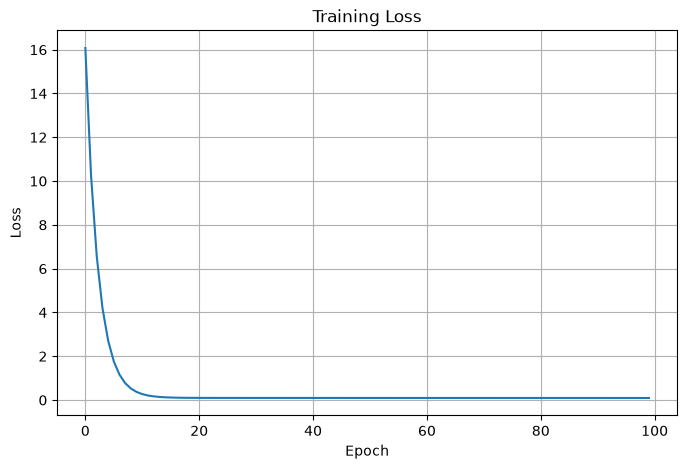

Final Loss: 0.09296382963657379


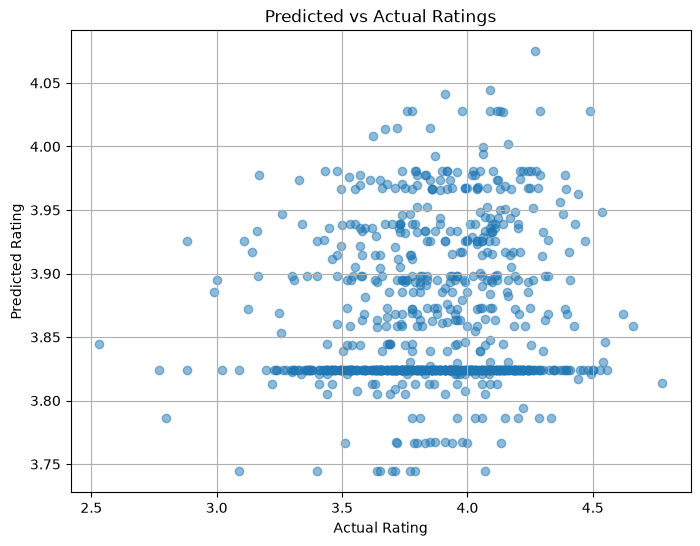

MAE = 0.2418394237756729


In [168]:
# RU: Импорт библиотек
# EN: Import libraries
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# RU: Подготовка данных
# EN: Prepare data
# ============================================================

# RU: Преобразование TF-IDF матрицы в тензор PyTorch
# EN: Convert TF-IDF matrix to PyTorch tensor
X = torch.from_numpy(
    Train_X_Tfidf.toarray().astype(np.float32)
).float()

# RU: Целевая переменная (рейтинг)
# EN: Target variable (rating)
y = torch.from_numpy(
    Corpus['rating'].values.astype(np.float32)
).float()

# RU: Приводим y к размерности (N,1)
# EN: Reshape y to (N,1)
y = y.view(-1, 1)

# RU: Проверяем размерности
# EN: Check dimensions
print("X shape:", X.shape)
print("y shape:", y.shape)

# ============================================================
# RU: Визуализация предсказаний модели
# EN: Visualize model predictions
# ============================================================

def plot_fit(title):

    with torch.no_grad():

        predictions = model(X)

        pred_np = predictions.numpy().flatten()
        actual_np = y.numpy().flatten()

        plt.figure(figsize=(8, 6))

        plt.scatter(
            actual_np,
            pred_np,
            alpha=0.5
        )

        plt.xlabel("Actual Rating")
        plt.ylabel("Predicted Rating")
        plt.title(title)

        plt.grid(True)

        plt.show()

# ============================================================
# RU: Создание модели линейной регрессии
# EN: Create linear regression model
# ============================================================

class LR(nn.Module):

    def __init__(self, input_size, output_size):

        super(LR, self).__init__()

        self.linear = nn.Linear(
            input_size,
            output_size
        )

    def forward(self, x):

        pred = self.linear(x)

        return pred

# ============================================================
# RU: Инициализация модели
# EN: Initialize model
# ============================================================

torch.manual_seed(1)

model = LR(
    X.shape[1],
    1
)

print(model)

# ============================================================
# RU: Получение параметров модели
# EN: Get model parameters
# ============================================================

[w, b] = model.parameters()

def get_params():

    return (
        w[0][0].item(),
        b[0].item()
    )

# ============================================================
# RU: Функция потерь и оптимизатор
# EN: Loss function and optimizer
# ============================================================

criterion = nn.MSELoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.1
)

# ============================================================
# RU: Обучение модели
# EN: Train model
# ============================================================

epochs = 100

losses = []

for i_epoch in range(epochs):

    # RU: Прямой проход
    # EN: Forward pass
    y_pred = model(X)

    # RU: Вычисление ошибки
    # EN: Compute loss
    loss = criterion(y_pred, y)

    print(
        f"{i_epoch+1}/{epochs} Epoch, Loss = {loss.item():.4f}"
    )

    losses.append(loss.item())

    # RU: Обнуляем градиенты
    # EN: Clear gradients
    optimizer.zero_grad()

    # RU: Обратное распространение ошибки
    # EN: Backpropagation
    loss.backward()

    # RU: Обновление параметров
    # EN: Update parameters
    optimizer.step()

# ============================================================
# RU: График функции потерь
# EN: Loss curve
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(losses)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")

plt.grid(True)

plt.show()

# ============================================================
# RU: Финальная ошибка
# EN: Final loss
# ============================================================

print("Final Loss:", losses[-1])

# ============================================================
# RU: Визуализация предсказаний
# EN: Visualize predictions
# ============================================================

plot_fit("Predicted vs Actual Ratings")

# 
with torch.no_grad():
    predictions = model(X)

    mae = torch.mean(
        torch.abs(predictions - y)
    )

print("MAE =", mae.item())

### Комментарий к качеству модели

Полученная модель демонстрирует низкую предсказательную способность (R² ≈ 0.004), то есть лишь незначительно превосходит наивную стратегию предсказания среднего рейтинга для всех книг.

Такой результат ожидаем и не является ошибкой реализации. В рамках данного примера использовалась очень упрощённая постановка задачи: рейтинг книги прогнозируется только на основе ограниченного набора текстовых признаков, сформированных по названию и автору с помощью TF-IDF. Подобные признаки содержат недостаточно информации для надёжного предсказания пользовательских оценок.

На практике рейтинг книги зависит от множества факторов: содержания произведения, популярности автора, жанра, маркетингового продвижения, времени публикации, количества и состава читателей, а также других данных, отсутствующих в используемом датасете. Поэтому даже корректно обученная модель не способна показать высокое качество на таком наборе признаков.

Цель данного ноутбука, вероятно, заключается не в построении конкурентоспособной модели рекомендаций, а в демонстрации основных этапов работы с текстовыми данными в PyTorch: подготовки признаков, создания модели, обучения и анализа результатов.

### Анализ результатов

Несмотря на успешную сходимость функции потерь, качество модели остаётся низким (R² ≈ 0.004). Фактически модель предсказывает значения, близкие к среднему рейтингу по выборке, и слабо различает книги между собой.

Это связано не столько с настройками модели, сколько с ограниченностью используемых признаков. Для прогнозирования рейтинга используются только TF-IDF-признаки, построенные по названию книги и имени автора. Такие данные не отражают качество произведения и предпочтения читателей, которые в действительности определяют итоговый рейтинг.

Следовательно, данный пример следует рассматривать как учебную демонстрацию применения методов обработки текста и построения простой модели регрессии, а не как попытку создать систему рекомендаций с высокой предсказательной точностью.